# 3 - Model selection, training and evaluation

For each of the nine targets (three forecasts x 1-3 days ahead) this notebook

1. compares **LightGBM** with three transparent **baselines**,
2. evaluates every model with an **expanding walk-forward** scheme (train on the
   past, test on the following month, repeat),
3. selects the winner per target and retrains it on all data, and
4. checks the new models against the served ones with the **quality gate**.

This is exactly what the monthly cloud job does (`climatelens train`, called by
Cloud Scheduler on the 1st of each month); the job additionally writes the model
bundle to Cloud Storage.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from climatelens.config import get_settings
from climatelens.data import latest_model_version, read_bundle_metrics, read_raw
from climatelens.evaluate import (
    MIN_TRAIN_DAYS,
    summarise,
    train_final,
    walk_forward_folds,
    walk_forward_predictions,
)
from climatelens.features import ALL_TARGETS, TARGETS, build_features, split_target, target_frame
from climatelens.models import LGBM_PARAMS, candidate_models, is_classification
from climatelens.pipeline import GATE_TOLERANCE, quality_gate

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIGURES = Path("notebooks/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
LABEL = {"target_frost": "Frost", "target_solar_kwh_m2": "Sunshine", "target_wind_speed": "Wind"}

settings = get_settings()
features = build_features(read_raw(settings.raw_uri))
print(
    f"feature table: {features.shape}, {features['date'].min():%Y-%m-%d} .. "
    f"{features['date'].max():%Y-%m-%d}"
)

feature table: (13656, 56), 2023-09-05 .. 2026-10-16


## 3.1 Candidate models

| Model | Idea | Used for |
|---|---|---|
| Persistence | the target day equals today | all targets |
| Climatology | smoothed historical average for the city and day of year (+/- 7 days) | all targets |
| Majority class | always the most frequent class ("no frost") | frost |
| **LightGBM** | gradient-boosted decision trees on the 42 features | all targets |

The baselines set the bar: a machine-learning model is only worth deploying if it
beats them. LightGBM is a strong, fast choice for tabular data and handles missing
values natively. Its settings are **fixed and regularised** - they are not tuned on
the evaluation folds, which would make the reported scores optimistic.

In [2]:
pd.Series(LGBM_PARAMS, name="value").to_frame().T

,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,subsample_freq,colsample_bytree,reg_lambda,random_state,n_jobs,deterministic,force_row_wise,verbose
value,400,0.03,15,40,0.8,1,0.8,1.0,42,1,True,True,-1


In [3]:
{LABEL[t]: [m.name for m in candidate_models(t)] for t in TARGETS}

{'Frost': ['persistence', 'climatology', 'majority_class', 'lightgbm'],
 'Sunshine': ['persistence', 'climatology', 'lightgbm'],
 'Wind': ['persistence', 'climatology', 'lightgbm']}

## 3.2 Walk-forward validation

Weather data is a time series, so rows are never shuffled: random cross-validation
would train on days *after* the test day and overstate the accuracy. Instead, each
fold trains on every row **before** a month boundary and tests on that month. The
first fold needs a full year of history, so that climatology has seen every season.

Each model is refitted from scratch in every fold on the blue window only and
scored on the orange month. The chart shows the folds of the frost target; sunshine
has 22 folds because DWD publishes radiation later (test months up to Jul 2026).

25 monthly folds, minimum training history 365 days
test months: Oct 2024 .. Oct 2026


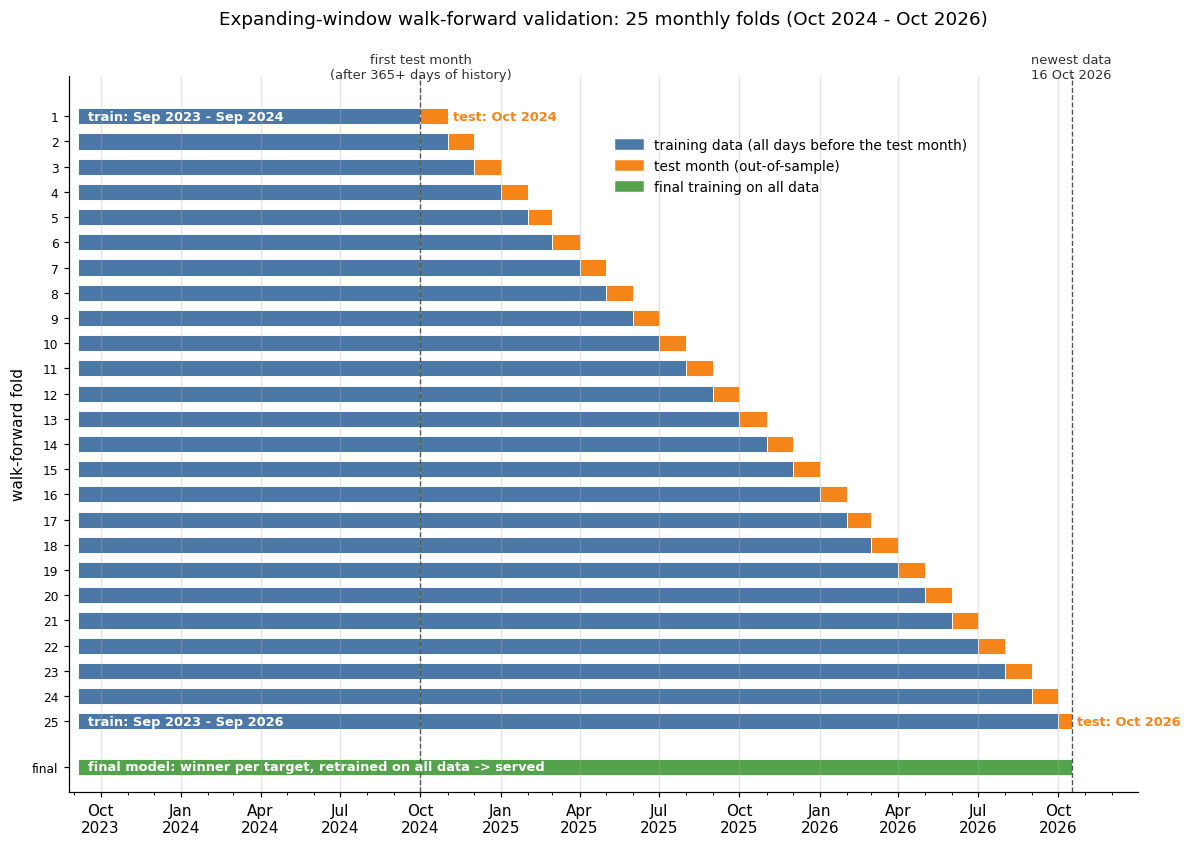

In [4]:
folds = walk_forward_folds(target_frame(features, "target_frost")["date"])
first_day, last_day = features["date"].min(), features["date"].max()
print(f"{len(folds)} monthly folds, minimum training history {MIN_TRAIN_DAYS} days")
print(f"test months: {folds[0].test_start:%b %Y} .. {folds[-1].test_start:%b %Y}")

TRAIN, TEST, FINAL = "#4c78a8", "#f58518", "#54a24b"
start = mdates.date2num(first_day)
end = mdates.date2num(last_day + pd.Timedelta(1, unit="D"))
bar = {"height": 0.64, "edgecolor": "white", "linewidth": 0.6}

fig, ax = plt.subplots(figsize=(11, 7.8))
for fold in folds:
    row = fold.index + 1
    t0, t1 = mdates.date2num(fold.test_start), mdates.date2num(fold.test_end)
    ax.barh(row, t0 - start, left=start, color=TRAIN, **bar)
    ax.barh(row, t1 - t0, left=t0, color=TEST, **bar)

# Labels on the first and the last fold.
for fold in (folds[0], folds[-1]):
    row = fold.index + 1
    train_end = fold.test_start - pd.Timedelta(1, unit="D")
    ax.text(
        start + 12,
        row,
        f"train: {first_day:%b %Y} - {train_end:%b %Y}",
        va="center",
        color="white",
        fontsize=8.5,
        fontweight="bold",
    )
    ax.text(
        mdates.date2num(fold.test_end) + 6,
        row,
        f"test: {fold.test_start:%b %Y}",
        va="center",
        color=TEST,
        fontsize=8.5,
        fontweight="bold",
    )

# The served model: the winner per target, refitted on all data.
final_row = len(folds) + 1.8
ax.barh(final_row, end - start, left=start, color=FINAL, **bar)
ax.text(
    start + 12,
    final_row,
    "final model: winner per target, retrained on all data -> served",
    va="center",
    color="white",
    fontsize=8.5,
    fontweight="bold",
)

for day, label in [
    (folds[0].test_start, f"first test month\n(after {MIN_TRAIN_DAYS}+ days of history)"),
    (last_day, f"newest data\n{last_day:%d %b %Y}"),
]:
    ax.axvline(mdates.date2num(day), color="#555555", ls="--", lw=0.9)
    ax.text(
        mdates.date2num(day), -0.4, label, ha="center", va="bottom", fontsize=8.5, color="#333333"
    )

ax.set_yticks([*range(1, len(folds) + 1), final_row])
ax.set_yticklabels([*(str(i) for i in range(1, len(folds) + 1)), "final"], fontsize=8)
ax.set_ylim(final_row + 1, -0.6)
ax.set_ylabel("walk-forward fold")
ax.set_xlim(start - 10, end + 75)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.grid(axis="x", which="major", alpha=0.35)
ax.grid(axis="y", visible=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(
    handles=[
        Patch(color=TRAIN, label="training data (all days before the test month)"),
        Patch(color=TEST, label="test month (out-of-sample)"),
        Patch(color=FINAL, label="final training on all data"),
    ],
    loc="upper left",
    bbox_to_anchor=(0.5, 0.93),
    fontsize=9,
    frameon=False,
)
ax.set_title(
    f"Expanding-window walk-forward validation: {len(folds)} monthly folds "
    f"({folds[0].test_start:%b %Y} - {folds[-1].test_start:%b %Y})",
    fontsize=12,
    pad=34,
)
plt.tight_layout()
plt.savefig(FIGURES / "walk_forward_scheme.png", dpi=200, bbox_inches="tight")
plt.show()

## 3.3 Evaluation of all models and targets

Every model is refitted from scratch in every fold (4 models x about 25 folds x
9 targets). This takes a few minutes on a laptop.

**Metrics.** Frost is a probability, scored with the **Brier score** (mean squared
error of the probability, lower is better) and accuracy at 50 %. Sunshine and wind
are scored with **MAE** and RMSE. **Skill** = 1 - score / reference score: the share
of the reference baseline's error that a model removes (climatology for frost,
persistence for sunshine and wind).

In [5]:
start = time.perf_counter()
predictions, evaluations = {}, {}
for target in ALL_TARGETS:
    predictions[target] = walk_forward_predictions(features, target)
    evaluations[target] = summarise(predictions[target], target)
print(f"walk-forward evaluation of {len(ALL_TARGETS)} targets: {time.perf_counter() - start:.0f} s")

walk-forward evaluation of 9 targets: 329 s


In [6]:
rows = []
for target, ev in evaluations.items():
    base, horizon = split_target(target)
    metric, reference = (
        ("brier", "climatology") if is_classification(target) else ("mae", "persistence")
    )
    scores = ev.overall
    row = {"forecast": LABEL[base], "days ahead": horizon, "metric": metric.upper()}
    row |= {
        m: scores[m][metric]
        for m in ("persistence", "climatology", "majority_class", "lightgbm")
        if m in scores
    }
    row["winner (served)"] = ev.best_model
    row["skill vs reference"] = f"{scores[ev.best_model][f'{metric}_skill_vs_{reference}']:+.1%}"
    row["reference"] = reference
    if is_classification(target):
        row["accuracy"] = f"{scores[ev.best_model]['accuracy']:.1%}"
    row["folds"] = ev.folds
    row["test period"] = f"{ev.test_start} .. {ev.test_end}"
    rows.append(row)
results = pd.DataFrame(rows)
results

,forecast,days ahead,metric,persistence,climatology,majority_class,lightgbm,winner (served),skill vs reference,reference,accuracy,folds,test period
0,Frost,1,BRIER,0.0908,0.1147,0.1760,0.0564,lightgbm,+50.8%,climatology,92.1%,25,2024-10-01 .. 2026-10-15
1,Frost,2,BRIER,0.1369,0.1144,0.1762,0.1019,lightgbm,+10.9%,climatology,85.9%,25,2024-10-01 .. 2026-10-14
2,Frost,3,BRIER,0.1595,0.1144,0.1764,0.1158,climatology,+0.0%,climatology,84.2%,25,2024-10-01 .. 2026-10-13
3,Sunshine,1,MAE,0.9419,1.0511,NaN,0.8427,lightgbm,+10.5%,persistence,NaN,22,2024-10-01 .. 2026-07-30
4,Sunshine,2,MAE,1.1153,1.0504,NaN,0.9632,lightgbm,+13.6%,persistence,NaN,22,2024-10-01 .. 2026-07-29
5,Sunshine,3,MAE,1.2035,1.0488,NaN,1.0239,lightgbm,+14.9%,persistence,NaN,22,2024-10-01 .. 2026-07-28
6,Wind,1,MAE,0.9201,0.9965,NaN,0.8296,lightgbm,+9.8%,persistence,NaN,25,2024-10-01 .. 2026-10-15
7,Wind,2,MAE,1.1161,0.9961,NaN,0.9646,lightgbm,+13.6%,persistence,NaN,25,2024-10-01 .. 2026-10-14
8,Wind,3,MAE,1.1734,0.9961,NaN,1.0087,climatology,+15.1%,persistence,NaN,25,2024-10-01 .. 2026-10-13


The 2-day rows are what the dashboard shows for "tomorrow". The test period for
sunshine ends earlier because DWD publishes radiation weeks after the other data.

These scores come from the local data copy. The deployed bundle was trained in the
cloud on its own copy, which DWD may have revised slightly since, so its published
scores (notebook 4, live `/metrics`) can differ in the third or fourth decimal.

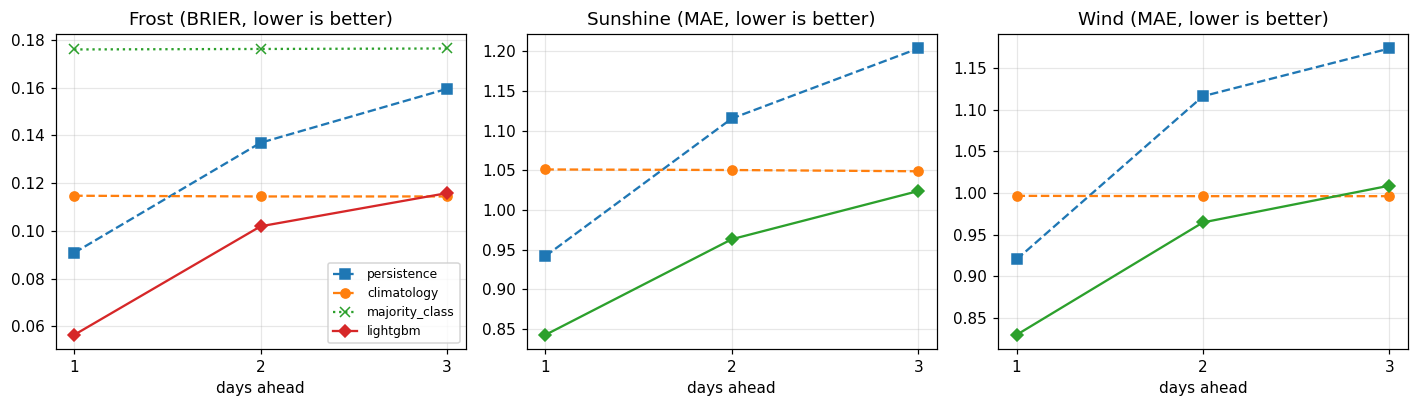

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, base in zip(axes, TARGETS, strict=True):
    metric = "brier" if is_classification(base) else "mae"
    for model, style in [
        ("persistence", "s--"),
        ("climatology", "o--"),
        ("majority_class", "x:"),
        ("lightgbm", "D-"),
    ]:
        ys = [
            evaluations[t].overall.get(model, {}).get(metric)
            for t in ALL_TARGETS
            if split_target(t)[0] == base
        ]
        if all(y is not None for y in ys):
            ax.plot([1, 2, 3], ys, style, label=model)
    ax.set_title(f"{LABEL[base]} ({metric.upper()}, lower is better)")
    ax.set_xlabel("days ahead")
    ax.set_xticks([1, 2, 3])
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "scores_by_horizon.png", bbox_inches="tight")
plt.show()

**Reading the results**

* LightGBM beats every baseline for all three forecasts 1 and 2 days ahead.
* Skill falls with the horizon, as expected for weather. For frost and wind
  **3 days ahead** the seasonal average (climatology) is as good as or better than the
  model - so climatology is served there. The pipeline always serves the measured
  winner, even when it is a baseline.
* Frost occurs on only about 15-18 % of days, so "never frost" already reaches over
  80 % accuracy. That is why the Brier score, not accuracy, is the primary frost metric.

### Per city (2 days ahead, the horizon used for "tomorrow")

In [8]:
city_rows = {}
for base in TARGETS:
    target = f"{base}_h2"
    metric, reference = (
        ("brier", "climatology") if is_classification(target) else ("mae", "persistence")
    )
    for city, by_model in evaluations[target].per_city.items():
        city_rows.setdefault(city, {})[f"{LABEL[base]} skill"] = by_model["lightgbm"][
            f"{metric}_skill_vs_{reference}"
        ]
per_city = pd.DataFrame(city_rows).T.sort_index()
print(
    f"LightGBM beats the reference in {(per_city > 0).sum().sum()} of {per_city.size} "
    "city-forecast combinations"
)
per_city.style.format("{:+.1%}").background_gradient(cmap="Greens", vmin=0, vmax=0.25)

LightGBM beats the reference in 36 of 36 city-forecast combinations


,Frost skill,Sunshine skill,Wind skill
berlin,+14.4%,+16.2%,+14.8%
bremen,+13.0%,+13.1%,+15.6%
cologne,+2.7%,+13.2%,+16.7%
dresden,+14.0%,+15.8%,+15.8%
essen,+9.5%,+13.0%,+13.1%
frankfurt,+3.8%,+14.5%,+3.1%
hamburg,+13.2%,+11.4%,+17.8%
hannover,+13.4%,+18.1%,+14.0%
leipzig,+12.0%,+19.2%,+10.1%
munich,+20.6%,+9.5%,+6.1%


### Is the frost probability trustworthy?

A reliability diagram groups the predicted probabilities and compares them with
how often frost actually occurred. Points on the diagonal mean "a 30 % forecast
comes true about 30 % of the time".

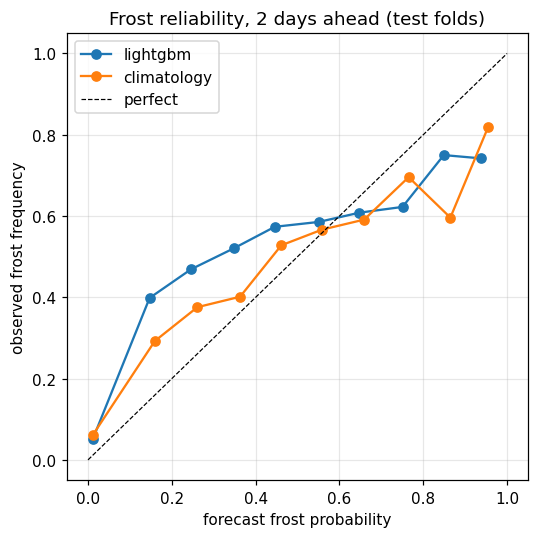

In [9]:
frost = predictions["target_frost_h2"]
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(5, 5))
for model in ("lightgbm", "climatology"):
    p = frost[frost["model"] == model]
    group = pd.cut(p["y_pred"], bins, include_lowest=True)
    stats = p.groupby(group, observed=True).agg(
        pred=("y_pred", "mean"), obs=("y_true", "mean"), n=("y_true", "size")
    )
    stats = stats[stats["n"] >= 20]
    ax.plot(stats["pred"], stats["obs"], "o-", label=model)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect")
ax.set_xlabel("forecast frost probability")
ax.set_ylabel("observed frost frequency")
ax.set_title("Frost reliability, 2 days ahead (test folds)")
ax.legend()
plt.tight_layout()
plt.show()

### Example: wind in Berlin, 2 days ahead (last test months)

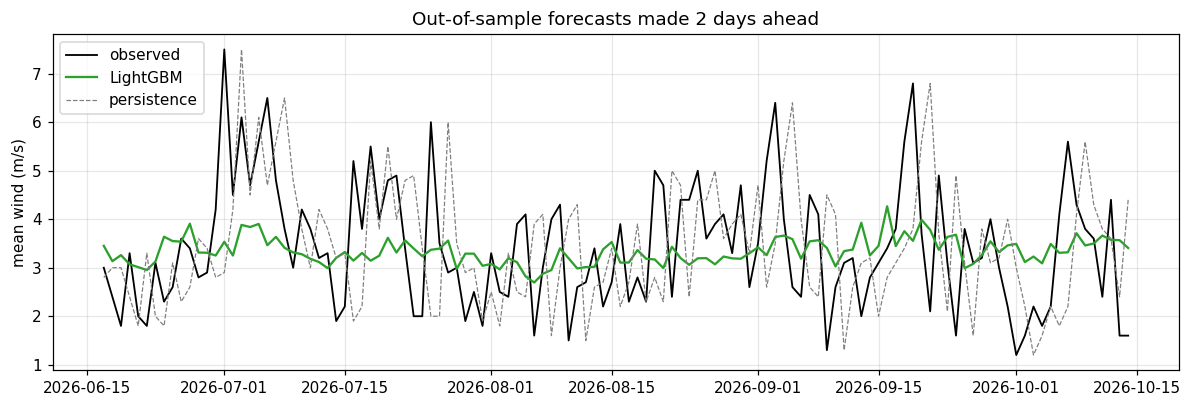

In [10]:
wind = predictions["target_wind_speed_h2"]
berlin = wind[wind["city"] == "berlin"].pivot_table(index="date", columns="model", values="y_pred")
observed = wind[(wind["city"] == "berlin") & (wind["model"] == "lightgbm")].set_index("date")
recent = berlin.index[-120:]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(recent, observed.loc[recent, "y_true"], color="k", lw=1.2, label="observed")
ax.plot(recent, berlin.loc[recent, "lightgbm"], color="tab:green", label="LightGBM")
ax.plot(
    recent,
    berlin.loc[recent, "persistence"],
    color="tab:gray",
    lw=0.8,
    ls="--",
    label="persistence",
)
ax.set_ylabel("mean wind (m/s)")
ax.set_title("Out-of-sample forecasts made 2 days ahead")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3.4 Final training

For each target, the walk-forward winner is retrained on **all** rows that have a
known target. These nine models form the bundle the service uses. Training is
deterministic: the same data gives the same models.

In [11]:
start = time.perf_counter()
trained = train_final(features, evaluations)
print(f"final training of {len(trained)} models: {time.perf_counter() - start:.1f} s")
pd.DataFrame(
    [
        {
            "target": t,
            "model": m.model.name,
            "rows": m.train_rows,
            "from": m.train_start,
            "to": m.train_end,
        }
        for t, m in trained.items()
    ]
)

final training of 9 models: 13.7 s


,target,model,rows,from,to
0,target_frost,lightgbm,13643,2023-09-05,2026-10-15
1,target_frost_h2,lightgbm,13631,2023-09-05,2026-10-14
2,target_frost_h3,climatology,13619,2023-09-05,2026-10-13
3,target_solar_kwh_m2,lightgbm,12100,2023-09-05,2026-07-30
4,target_solar_kwh_m2_h2,lightgbm,12090,2023-09-05,2026-07-29
5,target_solar_kwh_m2_h3,lightgbm,12080,2023-09-05,2026-07-28
6,target_wind_speed,lightgbm,13426,2023-09-05,2026-10-15
7,target_wind_speed_h2,lightgbm,13414,2023-09-05,2026-10-14
8,target_wind_speed_h3,climatology,13402,2023-09-05,2026-10-13


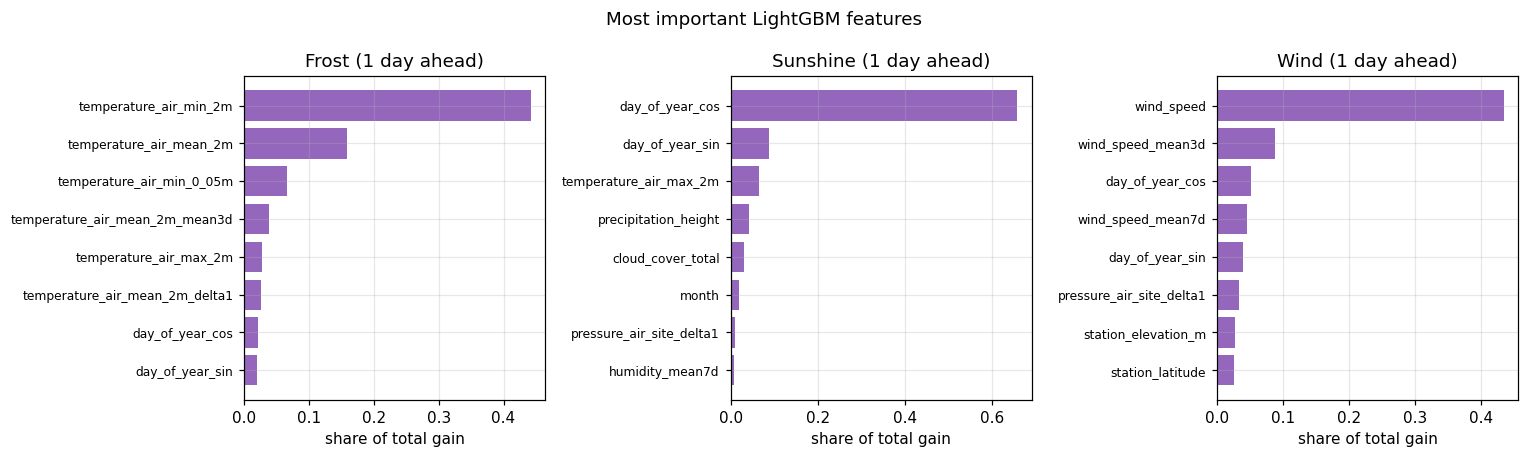

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, base in zip(axes, TARGETS, strict=True):
    importance = pd.Series(trained[base].model.feature_importance())
    top = (importance / importance.sum()).head(8)[::-1]
    ax.barh(top.index, top.values, color="tab:purple")
    ax.set_title(f"{LABEL[base]} (1 day ahead)")
    ax.set_xlabel("share of total gain")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Most important LightGBM features")
plt.tight_layout()
plt.savefig(FIGURES / "feature_importance.png", bbox_inches="tight")
plt.show()

The important features match meteorological intuition: current minimum
temperatures for frost, the season for solar energy, and current and recent wind
for wind.

## 3.5 Quality gate

Before a retrained bundle replaces the served one, the cloud job compares their
walk-forward scores. If any target's primary score (Brier or MAE) is more than
5 % worse, the new bundle is stored but **not published**, and the served model
stays in place.

In [13]:
served_version = latest_model_version(settings.models_uri)
served_metrics = read_bundle_metrics(settings.models_uri)
new_metrics = {t: ev.as_dict() for t, ev in evaluations.items()}
passed, checks = quality_gate(new_metrics, served_metrics)
print(f"compared with served bundle {served_version}; tolerance {GATE_TOLERANCE:.0%}")
print("gate passed" if passed else "gate FAILED - the new bundle would be held back")
pd.DataFrame(checks)

compared with served bundle 20261017T130211Z; tolerance 5%
gate passed


,target,new,served,change_pct,ok
0,target_frost,0.0564,0.0564,0.0,True
1,target_frost_h2,0.1019,0.1019,0.0,True
2,target_frost_h3,0.1144,0.1144,0.0,True
3,target_solar_kwh_m2,0.8427,0.8427,0.0,True
4,target_solar_kwh_m2_h2,0.9632,0.9632,0.0,True
5,target_solar_kwh_m2_h3,1.0239,1.0239,0.0,True
6,target_wind_speed,0.8296,0.8296,0.0,True
7,target_wind_speed_h2,0.9646,0.9646,0.0,True
8,target_wind_speed_h3,0.9961,0.9961,0.0,True


## Summary

| Step | How | Result |
|---|---|---|
| Model selection | LightGBM vs persistence, climatology, majority class | winner per target and horizon |
| Evaluation | expanding walk-forward, one fold per month, no shuffling | about 25 out-of-sample months |
| Result | LightGBM wins 1-2 days ahead for all forecasts | climatology served for frost and wind 3 days ahead |
| Training | winners refitted on all data, fixed parameters | 9 deterministic models |
| Release safety | quality gate, 5 % tolerance | no silent regressions |

In the cloud, `POST /jobs/train` runs these steps monthly and writes a versioned
bundle (models, manifest, metrics) to `gs://climatelens-iu-models/`. Notebook 4
checks the deployed service.